In [2]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split , KFold , cross_val_score
from sklearn.preprocessing import StandardScaler , OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [3]:
from sklearn.linear_model import LinearRegression , Ridge , Lasso
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

In [4]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [5]:
df = pd.read_csv("medical_cost.csv")
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [7]:
def vki_siniflandirma(vki):
  if vki < 18.5:
    return "Zayıf"
  elif 18.5 <= vki < 25.0:
    return "Normal"
  elif 25.0 <= vki < 30.0:
    return "Fazla_Kilolu"
  elif 30.0 <= vki < 35.0:
    return "Obez_1"
  elif 35.0 <= vki < 40.0:
    return "Obez_2"
  else:
    return "Obez_3"


df["vki_sinif"] = df["bmi"].apply(vki_siniflandirma)

In [8]:
X = df.drop("charges", axis=1)
y = df["charges"]

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [10]:
kategorik_sütunlar = ["sex", "smoker", "region", "vki_sinif"]
numerik_sütunlar = ["age", "bmi", "children"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerik_sütunlar),
        (
            "cat",
            OneHotEncoder(drop="first", handle_unknown="ignore"),
            kategorik_sütunlar,
        ),
    ]
)

In [11]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=1.0),
    "Random Forest": RandomForestRegressor(random_state=42),
    "XGBoost": XGBRegressor(random_state=42),
}

In [12]:
# modelleri eğitme, cross-validation ve test değerlendirmesi
print("--- Model Sonuçları ve K-Fold Cross-Validation Ortalamaları ---\n")
for name, model in models.items():
  # Pipeline kurulumu
  pipe = Pipeline(steps=[("preprocessor", preprocessor), ("model", model)])

  # K-Fold Cross-Validation (Veriyi 5 parçaya bölüp doğrulama yapıyoruz)
  cv = KFold(n_splits=5, shuffle=True, random_state=42)
  cv_scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="r2")

  # modeli tüm eğitim setiyle eğitip test setinde test etme
  pipe.fit(X_train, y_train)
  y_pred = pipe.predict(X_test)

  r2 = r2_score(y_test, y_pred)
  rmse = np.sqrt(mean_squared_error(y_test, y_pred))
  mae = mean_absolute_error(y_test, y_pred)

  print(f"🔹 {name}")
  print(
      f"   Test R2 Score      : {r2:.4f}  (CV Ort. R2: {cv_scores.mean():.4f})"
  )
  print(f"   Test RMSE (Hata)   : ${rmse:.2f}")
  print(f"   Test MAE (Sapma)   : ${mae:.2f}\n")

--- Model Sonuçları ve K-Fold Cross-Validation Ortalamaları ---

🔹 Linear Regression
   Test R2 Score      : 0.7795  (CV Ort. R2: 0.7442)
   Test RMSE (Hata)   : $5851.39
   Test MAE (Sapma)   : $4324.89

🔹 Ridge
   Test R2 Score      : 0.7800  (CV Ort. R2: 0.7444)
   Test RMSE (Hata)   : $5844.83
   Test MAE (Sapma)   : $4318.93

🔹 Lasso
   Test R2 Score      : 0.7797  (CV Ort. R2: 0.7443)
   Test RMSE (Hata)   : $5848.17
   Test MAE (Sapma)   : $4320.59

🔹 Random Forest
   Test R2 Score      : 0.8629  (CV Ort. R2: 0.8318)
   Test RMSE (Hata)   : $4613.70
   Test MAE (Sapma)   : $2618.95

🔹 XGBoost
   Test R2 Score      : 0.8422  (CV Ort. R2: 0.7936)
   Test RMSE (Hata)   : $4950.32
   Test MAE (Sapma)   : $2825.95



In [13]:
from sklearn.model_selection import RandomizedSearchCV

# random forest modeli ve denenecek hiperparametre grupları
rf_model = RandomForestRegressor(random_state=42)

# modelin test edeceği parametre kombinasyonları
param_dist = {
    "model__n_estimators": [100, 200, 400, 600, 800],
    "model__max_depth": [None, 10, 20, 30, 40],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ['sqrt', 'log2', 1.0]
}

# pipeline'ı tanımlama
pipe_rf = Pipeline(steps=[("preprocessor", preprocessor),
                          ("model", rf_model)])

# randomizedSearchCV kurulumu (20 farklı rastgele kombinasyonu 5-Fold ile test edeceğiz)
random_search = RandomizedSearchCV(
    estimator=pipe_rf,
    param_distributions=param_dist,
    n_iter=20,          # denenecek farklı kombinasyon sayısı
    cv=5,               # 5 Katlı çapraz doğrulama
    scoring='r2',
    random_state=42,
    n_jobs=-1           # bilgisayarın tüm işlemci çekirdeklerini kullanma (hızlı çalışması için)
)

random_search.fit(X_train, y_train)

# bulunan en iyi parametreleri ve skoru yazdırma
print("\n--- En İyi Parametreler ---")
for param, value in random_search.best_params_.items():
    print(f"{param}: {value}")

print(f"\nEn İyi CV Ortalaması (R2): {random_search.best_score_:.4f}")

# bulunan en iyi modeli test setinde değerlendirme
best_model = random_search.best_estimator_
y_pred_tuned = best_model.predict(X_test)

final_r2 = r2_score(y_test, y_pred_tuned)
final_rmse = np.sqrt(mean_squared_error(y_test, y_pred_tuned))
final_mae = mean_absolute_error(y_test, y_pred_tuned)

print(f"\n--- Optimize Edilmiş Modelin Test Çıktısı ---")
print(f"Test R2 Score : {final_r2:.4f}")
print(f"Test RMSE     : ${final_rmse:.2f}")
print(f"Test MAE      : ${final_mae:.2f}")


--- En İyi Parametreler ---
model__n_estimators: 600
model__min_samples_split: 10
model__min_samples_leaf: 4
model__max_features: 1.0
model__max_depth: 40

En İyi CV Ortalaması (R2): 0.8404

--- Optimize Edilmiş Modelin Test Çıktısı ---
Test R2 Score : 0.8772
Test RMSE     : $4365.68
Test MAE      : $2482.67


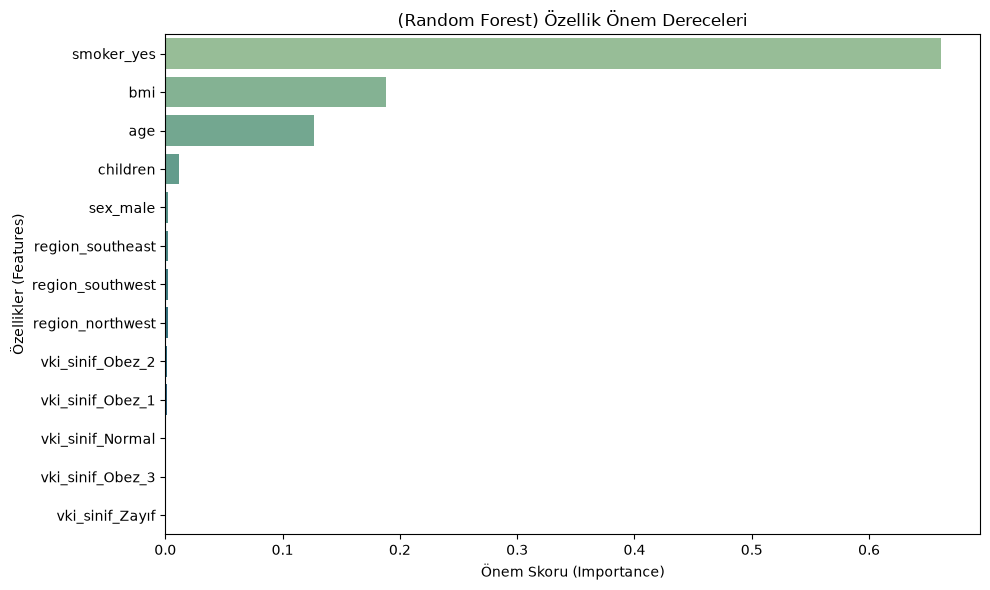

--- Özellik Önem Skorları (Sıralı) ---
         Feature  Importance
      smoker_yes    0.661491
             bmi    0.188547
             age    0.126393
        children    0.011544
        sex_male    0.002638
region_southeast    0.002132
region_southwest    0.001975
region_northwest    0.001969
vki_sinif_Obez_2    0.001099
vki_sinif_Obez_1    0.001092
vki_sinif_Normal    0.000961
vki_sinif_Obez_3    0.000158
 vki_sinif_Zayıf    0.000000


In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# vki sınıflandırma fonksiyonu
def vki_siniflandirma(vki):
    if vki < 18.5:
        return "Zayıf"
    elif 18.5 <= vki < 25.0:
        return "Normal"
    elif 25.0 <= vki < 30.0:
        return "Fazla_Kilolu"
    elif 30.0 <= vki < 35.0:
        return "Obez_1"
    elif 35.0 <= vki < 40.0:
        return "Obez_2"
    else:
        return "Obez_3"

df["vki_sinif"] = df["bmi"].apply(vki_siniflandirma)


X = df.drop("charges", axis=1)
y = df["charges"]


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# ön işleme pipeline kurulumu
kategorik_sütunlar = ["sex", "smoker", "region", "vki_sinif"]
numerik_sütunlar = ["age", "bmi", "children"]

preprocessor = ColumnTransformer(
    transformers=[
        ("numerik", StandardScaler(), numerik_sütunlar),
        ("kategorik", OneHotEncoder(drop="first", handle_unknown="ignore"), kategorik_sütunlar)
    ])

# seçtiğimiz (tuned) random forest modeli ile pipeline oluşturma
modelimiz = RandomForestRegressor(
    n_estimators=600,
    min_samples_split=10,
    min_samples_leaf=4,
    max_features=1.0,
    max_depth=40,
    random_state=42
)

model_pipe = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", modelimiz)
])

# modeli eğitme
model_pipe.fit(X_train, y_train)

# feature importance (Önem Derecesi) çıkarma ve görselleştirme
# ön işleme adımından dönüştürülen tüm sütun isimlerini alma
kategorik_encoder = model_pipe.named_steps["preprocessor"].named_transformers_["kategorik"]
encoded_kategorik_cols = list(kategorik_encoder.get_feature_names_out(kategorik_sütunlar))
all_feature_names = numerik_sütunlar + encoded_kategorik_cols

# modelin öğrenirken hangi özelliğe ne kadar ağırlık verdiğini çekme
# .feature_importances_ ---> Modeli .fit() fonksiyonu ile eğittikten sonra bu nitelik aktif olur.önce yaparsan hata veriyor
importances = model_pipe.named_steps["model"].feature_importances_

# dataFrame oluşturup büyükten küçüğe sıralama
feat_imp_df = pd.DataFrame({"Feature": all_feature_names, "Importance": importances})
feat_imp_df = feat_imp_df.sort_values(by="Importance", ascending=False)


plt.figure(figsize=(10, 6))
sns.barplot(x="Importance", y="Feature", data=feat_imp_df, palette="crest",hue="Feature")
plt.title('(Random Forest) Özellik Önem Dereceleri')
plt.xlabel("Önem Skoru (Importance)")
plt.ylabel("Özellikler (Features)")
plt.tight_layout()
plt.show()

# sıralı şekilde yazdırma
print("--- Özellik Önem Skorları (Sıralı) ---")
print(feat_imp_df.to_string(index=False))

In [15]:
import joblib

# modelimizi "sigorta_hesapla.joblib" ismiyle kaydediyoruz
joblib.dump(model_pipe, "sigorta_hesapla.joblib")

print("Model kaydedildi")

Model kaydedildi


In [16]:
# model özelliklerini kaydedelim fast api için

model_ozellikleri = X_train.columns.tolist()
joblib.dump(model_ozellikleri , "model_features.joblib")

print(f"özellik sayısı : {len(model_ozellikleri)}")

özellik sayısı : 7


In [17]:
print(model_ozellikleri)

['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'vki_sinif']
